In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler , LabelEncoder
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler


import warnings 
warnings.filterwarnings("ignore")

In [2]:
# Load the dataset
df = pd.read_excel('Data_file1.xlsx')

# Display the first few rows of dataset
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41,880,129.0,322,126,8.3252,452600,NEAR BAY
1,-122.22,37.86,21,7099,1106.0,2401,1138,8.3014,358500,NEAR BAY
2,-122.24,37.85,52,1467,190.0,496,177,7.2574,352100,NEAR BAY
3,-122.25,37.85,52,1274,235.0,558,219,5.6431,341300,NEAR BAY
4,-122.25,37.85,52,1627,280.0,565,259,3.8462,342200,NEAR BAY


In [3]:
#Exploratory Data Analysis 


In [4]:
#Display basic info about dataset
df.info ()

#Summary statistics of the dataset
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  int64  
 3   total_rooms         20640 non-null  int64  
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  int64  
 6   households          20640 non-null  int64  
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  int64  
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(4), int64(5), str(1)
memory usage: 1.7 MB


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [5]:
# check for missing values 

df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [6]:
# Check if 'ocean_proximity' column exists before converting to dummy variables
if 'ocean_proximity' in df.columns:
    # Convert categorical column 'ocean_proximity' into dummy variables
    df = pd.get_dummies(df, columns=['ocean_proximity'], drop_first=True, dtype=int)
else:
    # Print available columns to help identify the correct column name
    print("Column 'ocean_proximity' not found. Available columns:")
    print(df.columns.tolist())
    # If you find the correct column name, replace 'ocean_proximity' with it

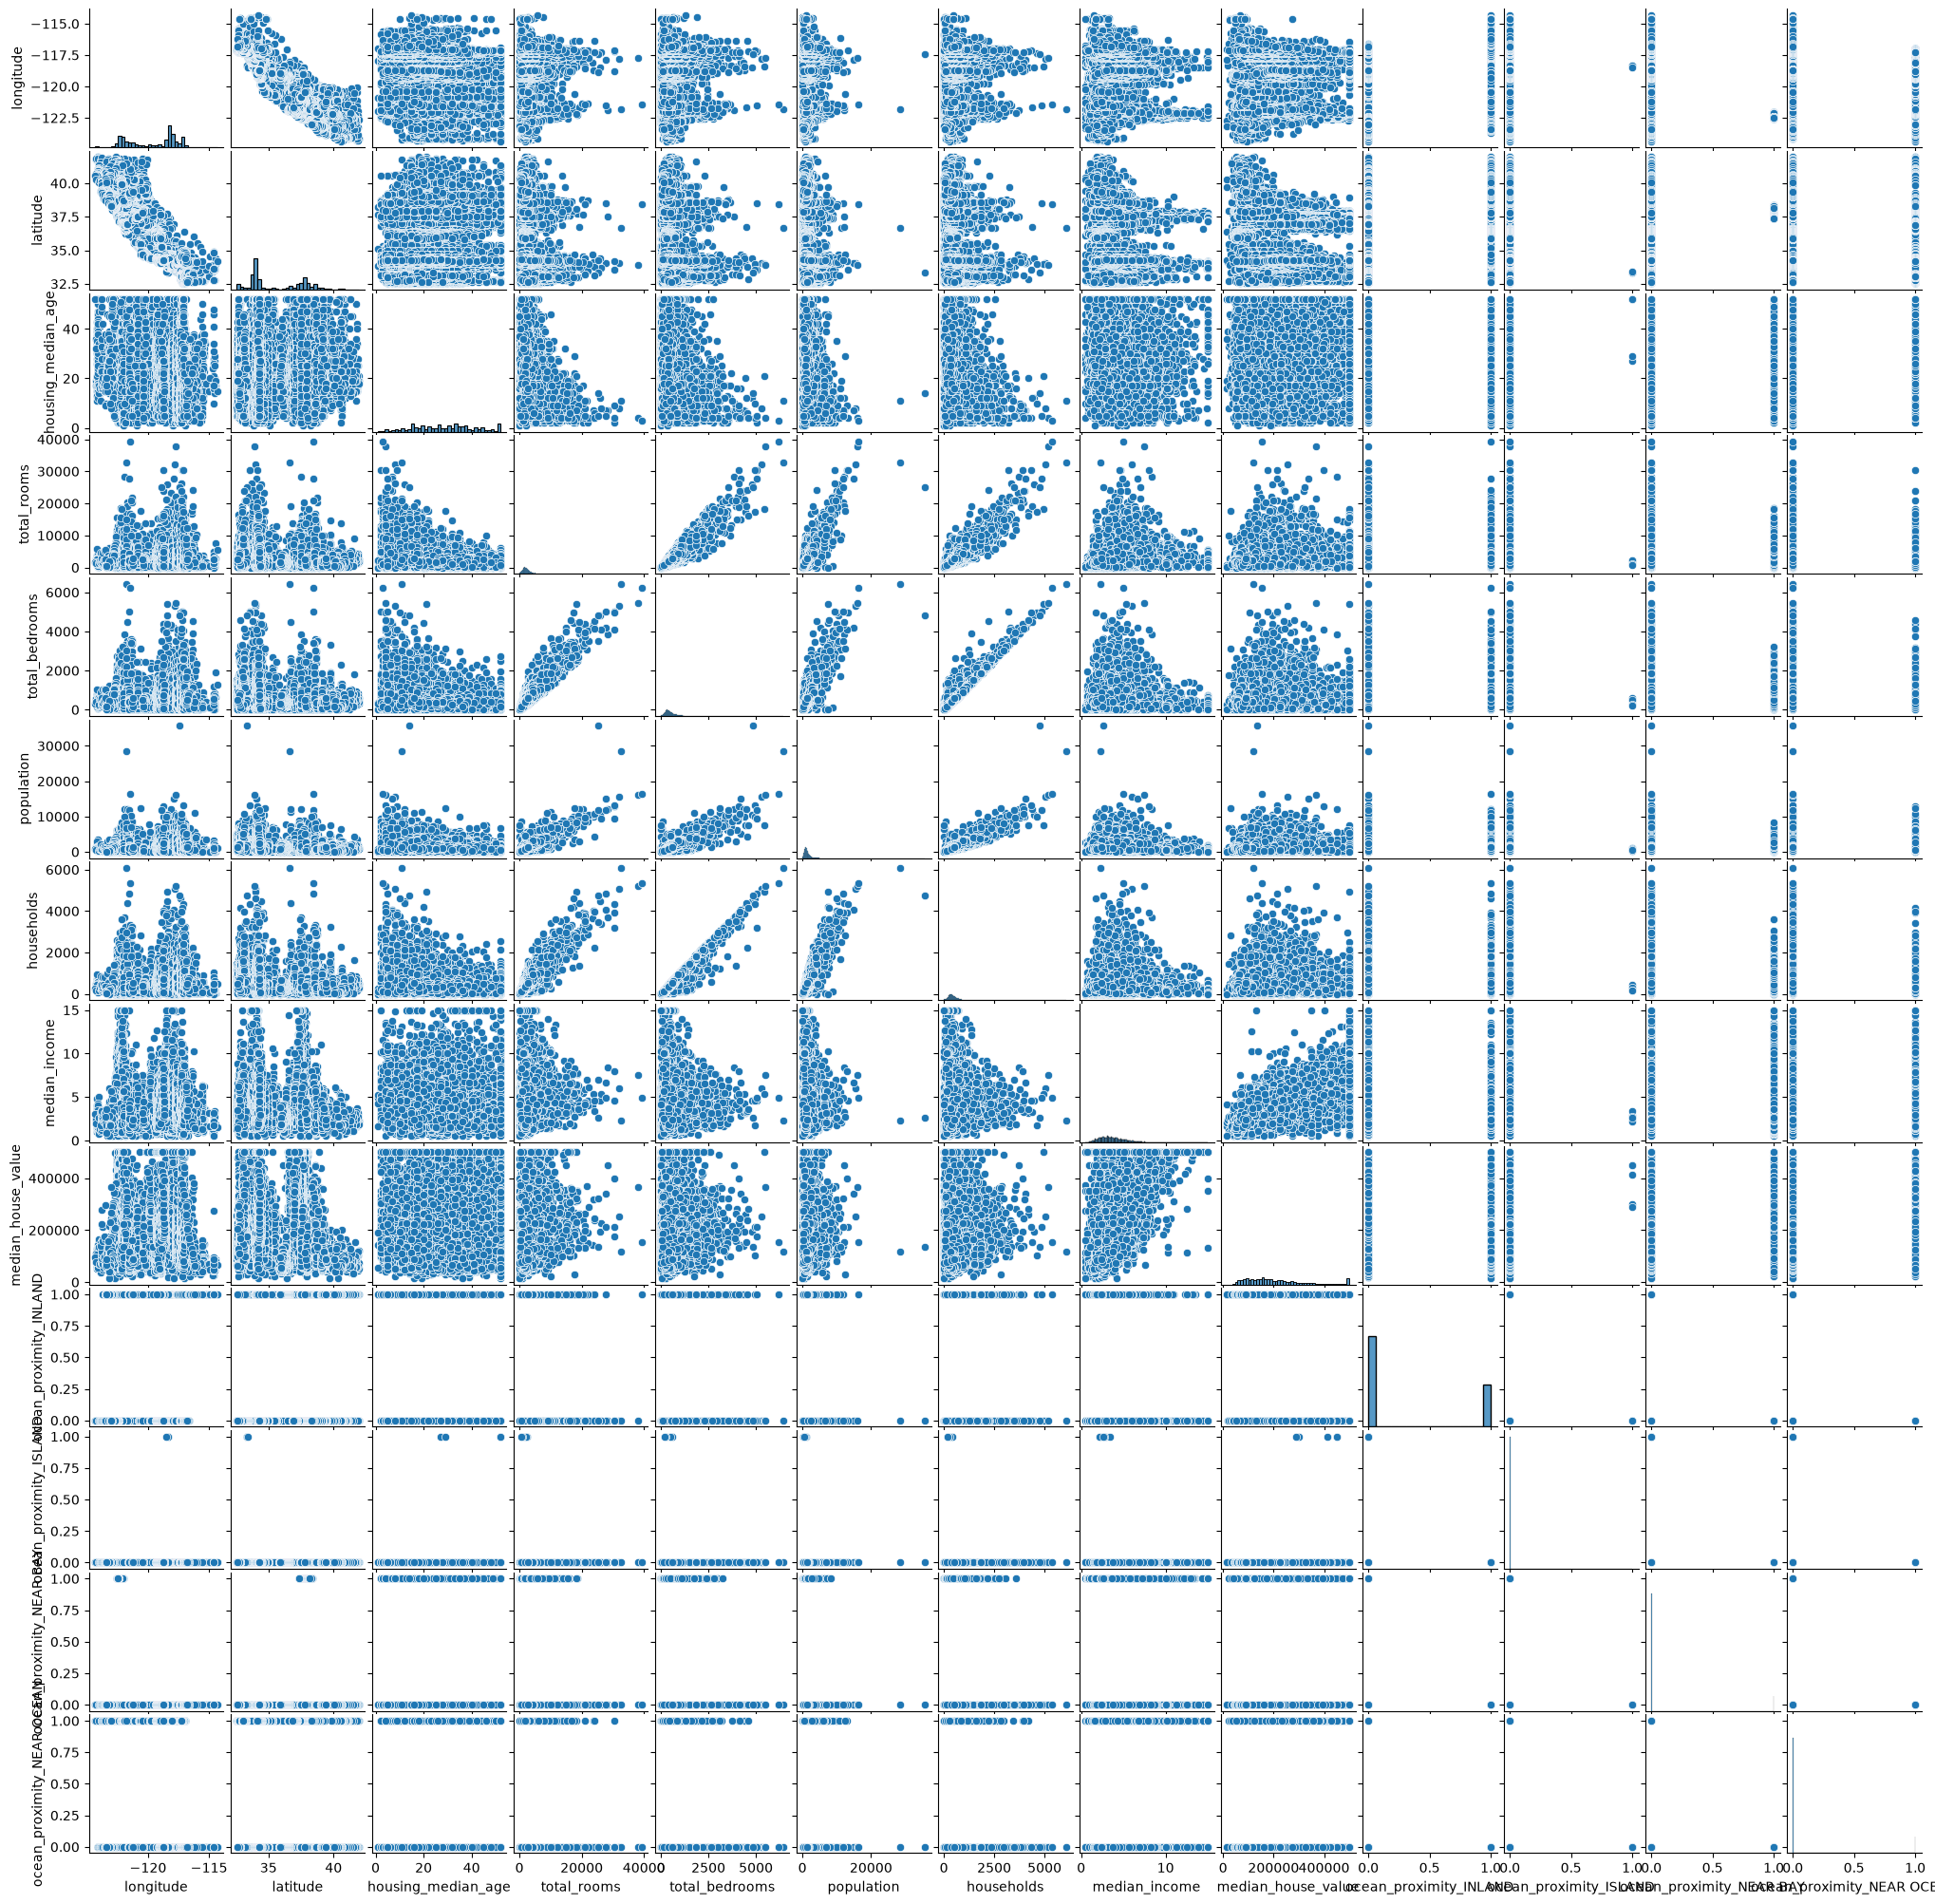

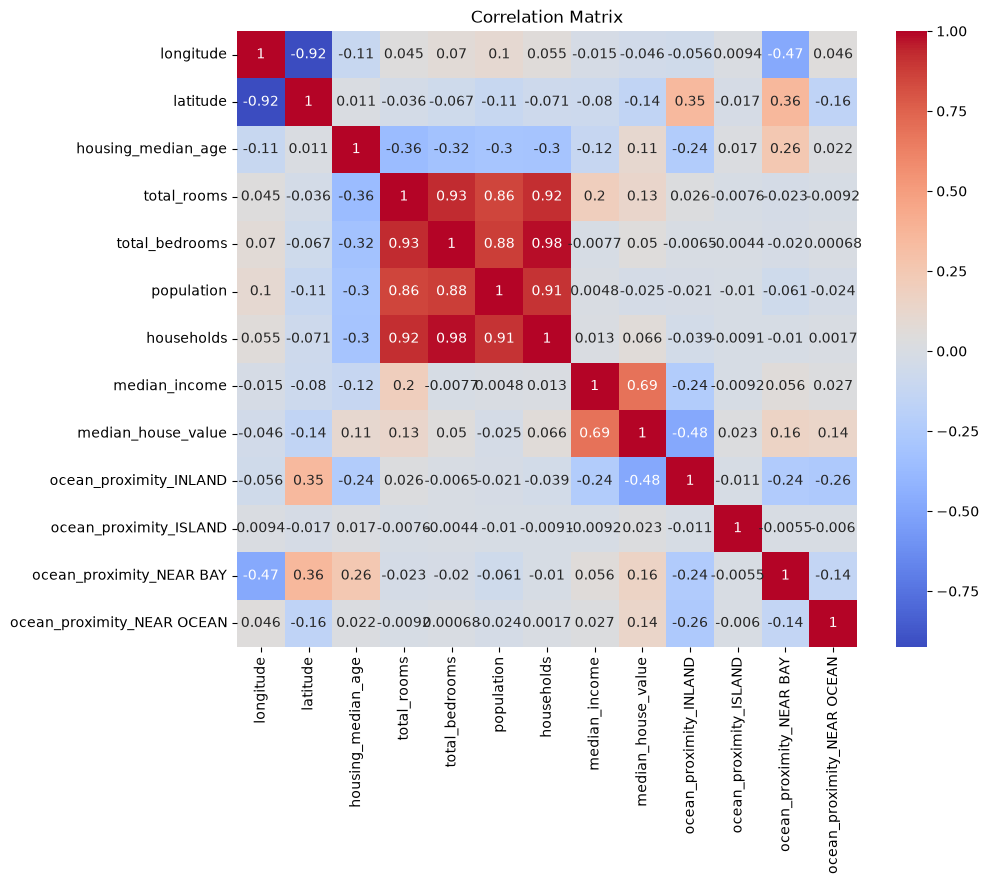

In [7]:
# Pairplot to visualize relationship between variables 
g = sns.pairplot(df, height=5)
g.fig.set_size_inches(20, 20)

plt.show()

# Correlation matrix 
correlation_matrix = df.corr()
plt.figure(figsize= (10,8))
sns.heatmap(correlation_matrix, annot = True, cmap ='coolwarm')
plt.title('Correlation Matrix')
plt.show()

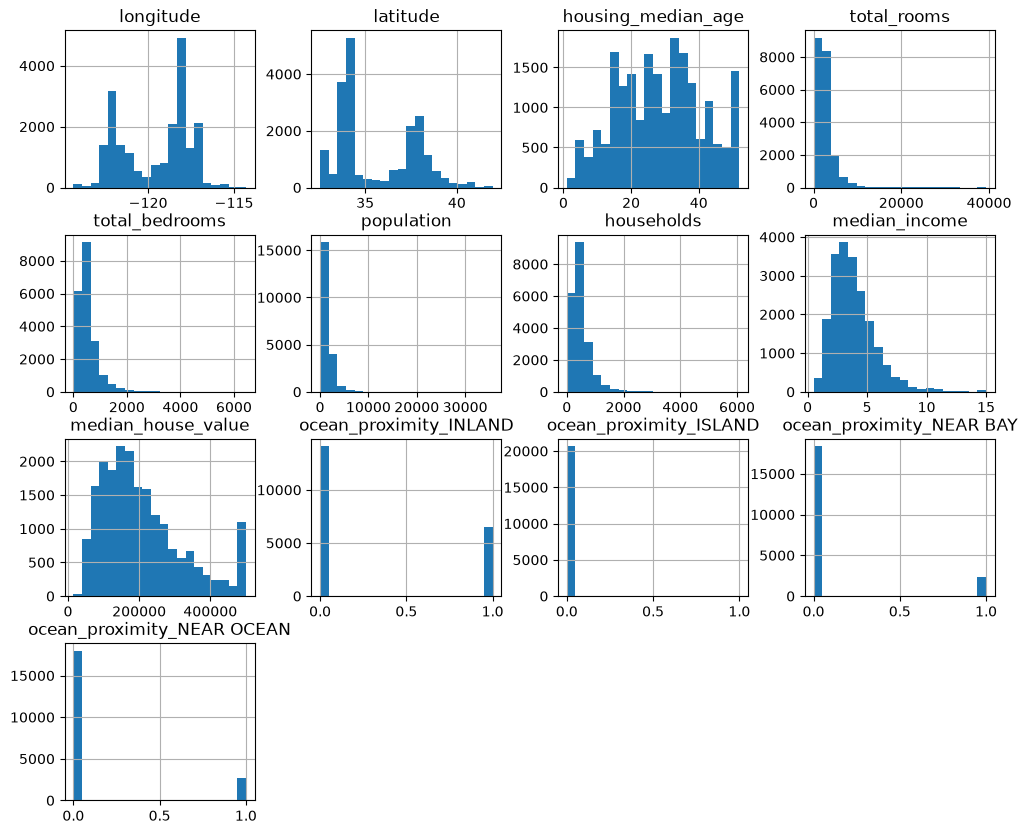

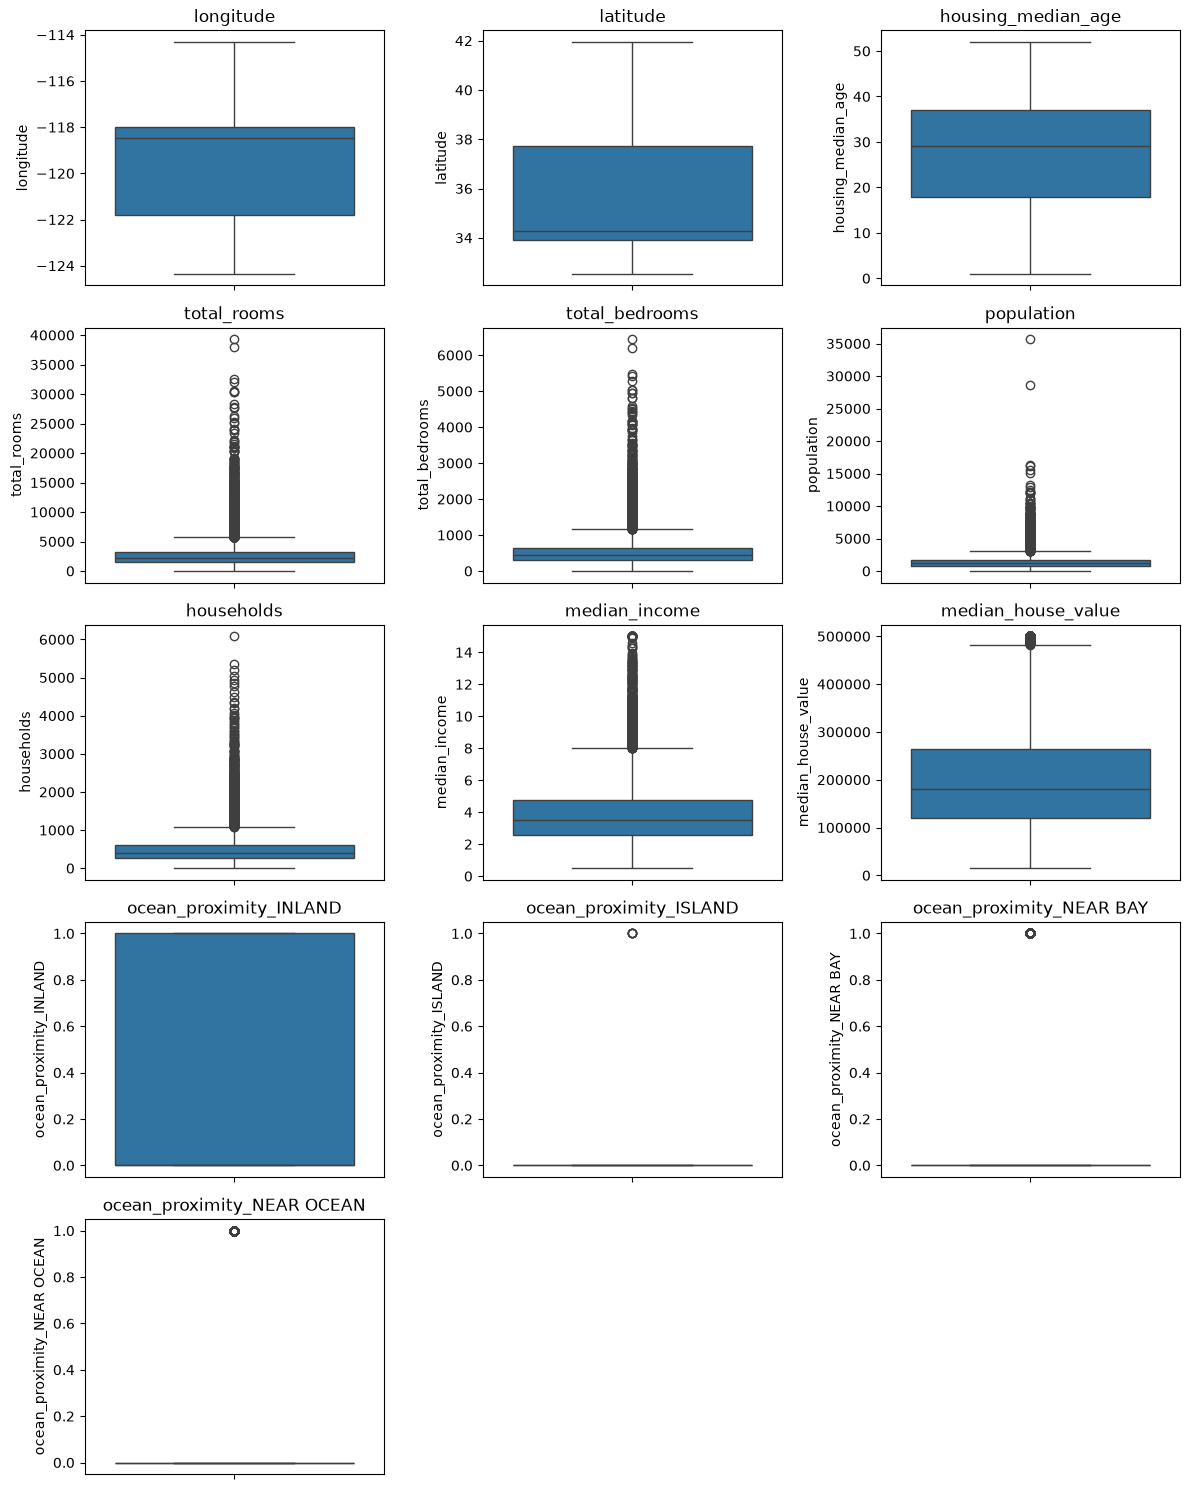

In [8]:
# Histograms of individual features 
df.hist(figsize = (12,10), bins=20)
plt.show()

# Box plots to check for outliers
# Calculate the number of columns to determine grid size
num_cols = len(df.columns)
num_rows = (num_cols + 2) // 3  # Calculate rows needed for 3 columns per row

plt.figure(figsize = (12, num_rows * 3))  # Adjust figure height based on rows
for i, column in enumerate(df.columns):
    plt.subplot(num_rows, 3, i+1)  # Use dynamic row count instead of fixed 3
    sns.boxplot(df[column])
    plt.title(column)
plt.tight_layout()
plt.show()

In [9]:
corr = df.corr(numeric_only=True)
print(corr['median_house_value'].sort_values(ascending=False))

median_house_value            1.000000
median_income                 0.688075
ocean_proximity_NEAR BAY      0.160284
ocean_proximity_NEAR OCEAN    0.141862
total_rooms                   0.134153
housing_median_age            0.105623
households                    0.065843
total_bedrooms                0.049686
ocean_proximity_ISLAND        0.023416
population                   -0.024650
longitude                    -0.045967
latitude                     -0.144160
ocean_proximity_INLAND       -0.484859
Name: median_house_value, dtype: float64


In [10]:
# SIMPLE LINEAR REGRESSION 

In [11]:
# Define the target variable and the predictor variable 
X = df[['median_income']]  #Predictor
y = df['median_house_value']     #Target

In [12]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state= 42)

In [13]:
# Handling null values in total_bedrooms

# Fill missing values in 'total_bedrooms' with the average value of that column
df["total_bedrooms"] = df["total_bedrooms"].fillna(
    df["total_bedrooms"].mean()
)

# Verify that null values are now 0
df["total_bedrooms"].isnull().sum()

np.int64(0)

In [14]:
# Create new scaled feature columns instead of overwriting
scaler = StandardScaler()
df[['latitude_scaled', 'longitude_scaled']] = scaler.fit_transform(df[['latitude', 'longitude']])

In [15]:
# Create and train the model

simple_model = LinearRegression()
simple_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[41933.85]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['median_income']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.446e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


Mean Squared Error:7091157771.76555
R^2 Score: 0.45885918903846656


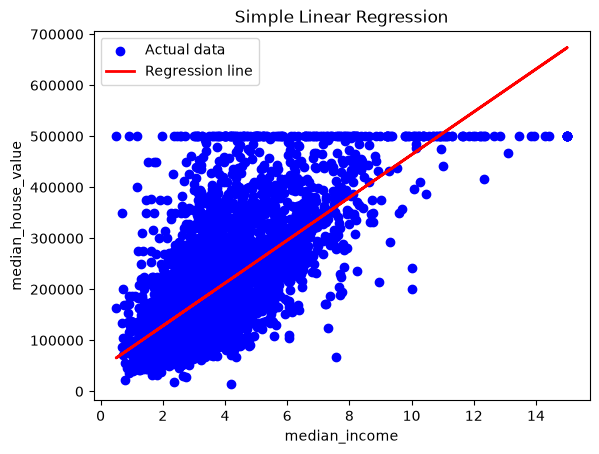

In [16]:
# Predictions 
y_pred = simple_model.predict(X_test)

# Evaluate the model 
print(f'Mean Squared Error:{mean_squared_error(y_test, y_pred)}')
print(f'R^2 Score: {r2_score(y_test, y_pred)}')

#Pot the regression line
plt.scatter(X_test, y_test, color='blue', label ='Actual data')
plt.plot(X_test, y_pred, color='red', linewidth=2, label='Regression line')
plt.xlabel('median_income')
plt.ylabel('median_house_value')
plt.title('Simple Linear Regression')
plt.legend()
plt.show()

In [17]:

# Input MedInc value from the user
medinc_value = float(input("Enter the median income:"))

# Convert the input to a 2D array for the model
medinc_value_array = np.array([[medinc_value]])

# Predict the house price using the trained model
predicted_price = simple_model.predict(medinc_value_array)

# Output the predictions 
print(f"The predicted median house price for medinc value of {medinc_value} is: ${predicted_price[0]:.2f}")

Enter the median income: 4.67899


The predicted median house price for medinc value of 4.67899 is: $240667.79


In [18]:
# MULTIPLE LINEAR REGRESSION

In [19]:
# Define multiple predicters
# Drop target and select everything else
X_multi = df.drop(columns=['median_house_value'])
y_multi = df['median_house_value']
    

In [20]:
# Split the dataset into training and testing sets
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(X_multi, y_multi, test_size=0.2, random_state=42)

In [21]:
# Create and train the model

multi_model = LinearRegression()
multi_model.fit (X_train_multi, y_train_multi)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](14,)","[-21485.55,-20889.42, 1102.19,..., 3431.14, -9780.15,-10724.1 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](14,)","['longitude','latitude','housing_median_age',..., 'ocean_proximity_NEAR OCEAN','latitude_scaled','longitude_scaled']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.799e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,14
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(12)


In [22]:
#Predictions
y_pred_multi = multi_model.predict(X_test_multi)

# Evaluate the model
print(f'Mean Squared Error: {mean_squared_error(y_test_multi, y_pred_multi)}')
print(f'R^2 Score: {r2_score(y_test_multi, y_pred_multi)}')

Mean Squared Error: 4904399775.949273
R^2 Score: 0.6257351821159707


In [23]:
# Display the coefficents of the model
coefficients = pd.DataFrame(multi_model.coef_, X_multi.columns, columns=['Coefficient'])
print(coefficients)

                              Coefficient
longitude                   -21485.547326
latitude                    -20889.419259
housing_median_age            1102.185084
total_rooms                     -6.021506
total_bedrooms                 102.789395
population                     -38.172906
households                      48.252753
median_income                39473.975175
ocean_proximity_INLAND      -39786.656161
ocean_proximity_ISLAND      136125.072615
ocean_proximity_NEAR BAY     -5136.642217
ocean_proximity_NEAR OCEAN    3431.140073
latitude_scaled              -9780.145543
longitude_scaled            -10724.096642
